In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,f1_score
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder,StandardScaler

In [2]:
RANDOM_STATE = 24  # Remember to remove at the time of promotion to production(RANDOM_STATE = None) 
np.random.seed(RANDOM_STATE)
rng = np.random.default_rng(seed = RANDOM_STATE)

NOISE = 0.2
N_EPOCHS = 100 # Number of Epochs
ALPHA = .001  # Learning Rate 
N_SAMPLES = 1000  # number of sample to create
TEST_SIZE = 0.2

params = {
    'legend.fontsize':'medium',
    'figure.figsize':(15,6),
    'axes.labelsize':'medium',
    'axes.titlesize':'medium',
    'xtick.labelsize':'medium',
    'ytick.labelsize':'medium'
}
plt.rcParams.update(params)
CMAP = plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid') 

In [3]:
physical_devices = tf.config.list_physical_devices('GPU')
if len(physical_devices) > 0:
    tf.config.experimental.set_memory_growth(physical_devices[0], True)


In [4]:
data_df=pd.read_csv("wine.csv",header=None)
data_df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [5]:
data_df.shape

(178, 14)

In [6]:
for col in data_df.columns:
    print(f'Col: {col}, {data_df[col].unique()}')

Col: 0, [14.23 13.2  13.16 14.37 13.24 14.2  14.39 14.06 14.83 13.86 14.1  14.12
 13.75 14.75 14.38 13.63 14.3  13.83 14.19 13.64 12.93 13.71 12.85 13.5
 13.05 13.39 13.3  13.87 14.02 13.73 13.58 13.68 13.76 13.51 13.48 13.28
 13.07 14.22 13.56 13.41 13.88 14.21 13.9  13.94 13.82 13.77 13.74 13.29
 13.72 12.37 12.33 12.64 13.67 12.17 13.11 13.34 12.21 12.29 13.49 12.99
 11.96 11.66 13.03 11.84 12.7  12.   12.72 12.08 12.67 12.16 11.65 11.64
 12.69 11.62 12.47 11.81 12.6  12.34 11.82 12.51 12.42 12.25 12.22 11.61
 11.46 12.52 11.76 11.41 11.03 12.77 11.45 11.56 11.87 12.07 12.43 11.79
 12.04 12.86 12.88 12.81 12.53 12.84 13.36 13.52 13.62 12.87 13.32 13.08
 12.79 13.23 12.58 13.17 13.84 12.45 14.34 12.36 13.69 12.96 13.78 13.45
 12.82 13.4  12.2  14.16 13.27 14.13]
Col: 1, [1.71 1.78 2.36 1.95 2.59 1.76 1.87 2.15 1.64 1.35 2.16 1.48 1.73 1.81
 1.92 1.57 1.59 3.1  1.63 3.8  1.86 1.6  2.05 1.77 1.72 1.9  1.68 1.5
 1.66 1.83 1.53 1.8  1.65 3.99 3.84 1.89 3.98 4.04 3.59 2.02 1.75 1.67
 1.7 

In [7]:
data_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       178 non-null    float64
 1   1       178 non-null    float64
 2   2       178 non-null    float64
 3   3       178 non-null    float64
 4   4       178 non-null    int64  
 5   5       178 non-null    float64
 6   6       178 non-null    float64
 7   7       178 non-null    float64
 8   8       178 non-null    float64
 9   9       178 non-null    float64
 10  10      178 non-null    float64
 11  11      178 non-null    float64
 12  12      178 non-null    int64  
 13  13      178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB


<Axes: >

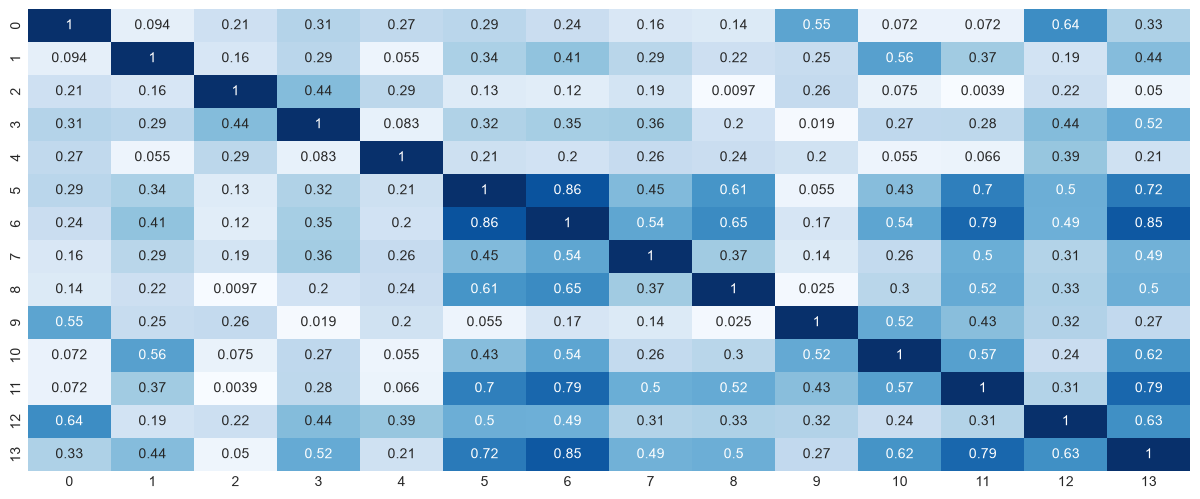

In [8]:
fig ,ax=plt.subplots(figsize=(15,6))
sns.heatmap(data=data_df.corr().abs(),ax=ax,cmap='Blues',
            annot=True,
            fmt='.2g',
            cbar=False)

In [9]:
labels=data_df[data_df.columns[-1]]
features_df=data_df.drop(data_df.columns[-1],axis=1)
features_df.shape,labels.shape

((178, 13), (178,))

In [10]:
X_train,X_test,y_train,y_test=train_test_split(features_df,
                                               labels,
                                               test_size=TEST_SIZE,
                                               random_state=RANDOM_STATE,
                                               stratify=labels)

In [11]:
sc=StandardScaler()
X_train=sc.fit_transform(X_train)
X_test=sc.transform(X_test)
le=LabelEncoder()
y_train=le.fit_transform(y_train)
y_test=le.transform(y_test)

In [12]:
tf.keras.layers.Dense?

Init signature:
tf.keras.layers.Dense(
    units,
    activation=None,
    use_bias=True,
    kernel_initializer='glorot_uniform',
    bias_initializer='zeros',
    kernel_regularizer=None,
    bias_regularizer=None,
    activity_regularizer=None,
    kernel_constraint=None,
    bias_constraint=None,
    lora_rank=None,
    lora_alpha=None,
    quantization_config=None,
    **kwargs,
)
Docstring:     
Just your regular densely-connected NN layer.

`Dense` implements the operation:
`output = activation(dot(input, kernel) + bias)`
where `activation` is the element-wise activation function
passed as the `activation` argument, `kernel` is a weights matrix
created by the layer, and `bias` is a bias vector created by the layer
(only applicable if `use_bias` is `True`). When this layer is
followed by a `BatchNormalization` layer, it is recommended to set
`use_bias=False` as `BatchNormalization` has its own bias term.

Note: If the input to the layer has a rank greater than 2, `Dense`
computes

In [13]:
model=tf.keras.Sequential(
    [
        tf.keras.Input(shape=(X_train.shape[1],)),  # Input layer
        tf.keras.layers.Dense(8, activation = 'relu'), # Hidden layer
        tf.keras.layers.Dense(3) # Output layer  
    ]
)

In [14]:
prediction=model(X_train[:1])
prediction

<tf.Tensor: shape=(1, 3), dtype=float32, numpy=array([[ 0.4999889 , -0.6565612 ,  0.27072462]], dtype=float32)>

In [15]:
tf.nn.softmax(prediction).numpy

<bound method _EagerTensorBase.numpy of <tf.Tensor: shape=(1, 3), dtype=float32, numpy=array([[0.4740038 , 0.14910716, 0.3768891 ]], dtype=float32)>>

In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 8)                   │             112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │              27 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 139 (556.00 B)

 Trainable params: 139 (556.00 B)

 Non-trainable params: 0 (0.00 B)

In [17]:
loss_fn=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

optimizer = tf.keras.optimizers.Adam(learning_rate = ALPHA)

In [18]:
model.compile(optimizer = optimizer, 
              loss = loss_fn,
              metrics = ['accuracy'])

In [19]:
history = model.fit(X_train, y_train, 
                    validation_data = [X_test, y_test],
                    epochs = N_EPOCHS)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - accuracy: 0.2254 - loss: 1.6745 - val_accuracy: 0.2778 - val_loss: 1.5957
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.2324 - loss: 1.6177 - val_accuracy: 0.2778 - val_loss: 1.5396
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.2465 - loss: 1.5657 - val_accuracy: 0.2778 - val_loss: 1.4877
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.2746 - loss: 1.5147 - val_accuracy: 0.3333 - val_loss: 1.4381
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.2887 - loss: 1.4678 - val_accuracy: 0.3611 - val_loss: 1.3909
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.2958 - loss: 1.4223 - val_accuracy: 0.3611 - val_loss: 1.3467
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3239 - loss: 1.3793 - val_accuracy: 0.3611 - val_loss: 1.3049
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.3451 - loss: 1.3383 - val_accuracy: 0.3889 - val_loss:

In [20]:
loss_df=pd.DataFrame(history.history)
loss_df

,accuracy,loss,val_accuracy,val_loss
0,0.225352,1.674465,0.277778,1.595696
1,0.232394,1.617719,0.277778,1.539605
2,0.246479,1.565650,0.277778,1.487690
3,0.274648,1.514700,0.333333,1.438100
4,0.288732,1.467847,0.361111,1.390856
...,...,...,...,...
95,0.992958,0.137984,0.944444,0.165347
96,0.992958,0.135268,0.944444,0.163204
97,0.992958,0.132701,0.944444,0.160989
98,0.992958,0.130264,0.944444,0.158808


In [21]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.colors import ListedColormap

def fn_plot_tf_hist(hist_df):
    """
    Plots training history with side-by-side Loss and Accuracy curves.
    Automatically highlights the best epoch based on minimum validation loss.
    """
    # 1. Create the figure and axes layout
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    
    # Custom colormap: Blue for training, Red/Crimson for validation
    CMAP = ListedColormap(['#3F51B5', '#D32F2F'])
    
    # 2. Get columns by index to eliminate any column naming errors
    # Expected positions: y1=accuracy, y2=loss, y3=val_accuracy, y4=val_loss
    y1 = hist_df.columns[0]
    y2 = hist_df.columns[1]
    y3 = hist_df.columns[2]
    y4 = hist_df.columns[3]

    # 3. Find the best epoch details based on minimum validation loss
    min_loss_row = hist_df[hist_df[y4] == hist_df[y4].min()]
    best_epoch = min_loss_row.index[0]
    min_loss = min_loss_row[y4].values[0]
    best_acc = min_loss_row[y3].values[0]

    # ==========================================
    # LEFT PLOT: LOSS CURVE
    # ==========================================
    ax0 = axes[0]
    hist_df.plot(y=[y2, y4], ax=ax0, colormap=CMAP)
    
    # Layout and Labels
    ax0.set_title("Loss Curve", fontsize=12)
    ax0.set_xlabel("Epochs")
    ax0.set_ylabel("Loss")
    ax0.grid(True, alpha=0.3)
    
    # Green dash-dot vertical line at the best epoch
    ax0.axvline(x=best_epoch, color='g', linestyle='-.', linewidth=2)
    
    # Text box for final epoch loss metrics (top left)
    txtFmt_loss = "Loss:\n train: {:6.4f}\n  test: {:6.4f}"
    txtstr_loss = txtFmt_loss.format(hist_df.iloc[-1][y2], hist_df.iloc[-1][y4])
    ax0.text(0.2, 0.85, txtstr_loss, transform=ax0.transAxes, fontsize=10,
             bbox=dict(boxstyle="round,pad=0.5", facecolor="cyan", alpha=0.2, edgecolor="grey"))
    
    # Robust annotation pointing to the minimum validation loss
    ax0.annotate(f'Min: {min_loss:.4f}', 
                 xy=(best_epoch, min_loss), 
                 xytext=(-60, 45),            # Fixed pixel offset to the left and up
                 textcoords='offset points',  # Prevents squishing on different data scales
                 arrowprops=dict(facecolor='cyan', shrink=0.1, width=2, headwidth=8),
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="cyan", alpha=0.2, edgecolor="grey"),
                 ha='right', va='bottom')

    # ==========================================
    # RIGHT PLOT: ACCURACY CURVE
    # ==========================================
    ax1 = axes[1]
    hist_df.plot(y=[y1, y3], ax=ax1, colormap=CMAP)
    
    # Layout and Labels
    ax1.set_title("Accuracy Curve", fontsize=12)
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Accuracy")
    ax1.grid(True, alpha=0.3)
    
    # Green dash-dot vertical line at the best epoch
    ax1.axvline(x=best_epoch, color='g', linestyle='-.', linewidth=2)
    
    # Text box for final epoch accuracy metrics (bottom center)
    txtFmt_acc = "Accuracy:\n train: {:6.4f}\n  test: {:6.4f}"
    txtstr_acc = txtFmt_acc.format(hist_df.iloc[-1][y1], hist_df.iloc[-1][y3])
    ax1.text(0.3, 0.15, txtstr_acc, transform=ax1.transAxes, fontsize=10,
             bbox=dict(boxstyle="round,pad=0.5", facecolor="cyan", alpha=0.2, edgecolor="grey"))
    
    # Robust annotation pointing to accuracy at the best epoch
    ax1.annotate(f'Best: {best_acc:.4f}', 
                 xy=(best_epoch, best_acc), 
                 xytext=(-60, -35),           # Fixed pixel offset to the left and down
                 textcoords='offset points',  # Prevents squishing when accuracy hugs 1.0
                 arrowprops=dict(facecolor='cyan', shrink=0.1, width=2, headwidth=8),
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="cyan", alpha=0.2, edgecolor="grey"),
                 ha='right', va='top')

    # Final rendering tweaks
    plt.tight_layout()
    plt.show()


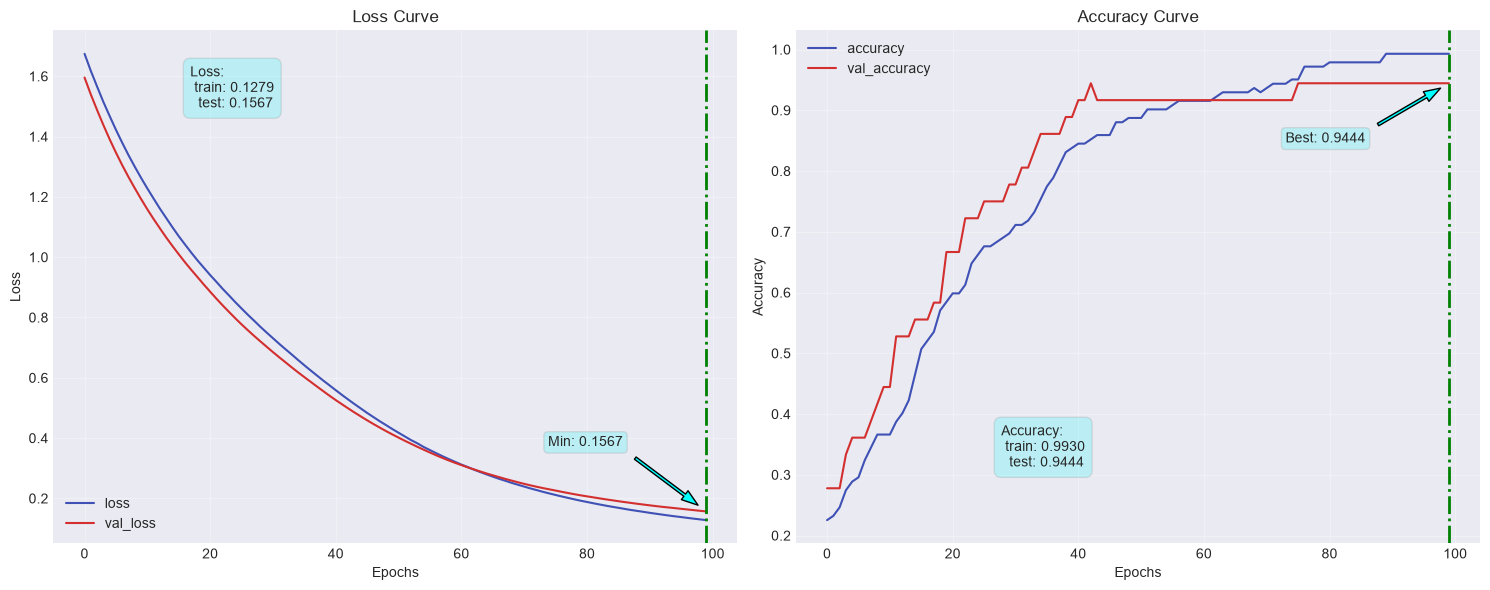

In [22]:
fn_plot_tf_hist(loss_df)

In [23]:
model.evaluate(X_train,y_train,verbose=2)

5/5 - 0s - 18ms/step - accuracy: 0.9930 - loss: 0.1263


[0.12634514272212982, 0.9929577708244324]

In [24]:
y_pred=model.predict(X_train)
y_pred.shape

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


(142, 3)

In [25]:
y_test.shape,y_train.shape,y_pred.shape

((36,), (142,), (142, 3))

In [26]:
f_score=f1_score(y_true=y_train,y_pred=y_pred.argmax(axis=1),average='weighted')
accuracy_score(y_train,y_pred.argmax(axis=1))

0.9929577464788732

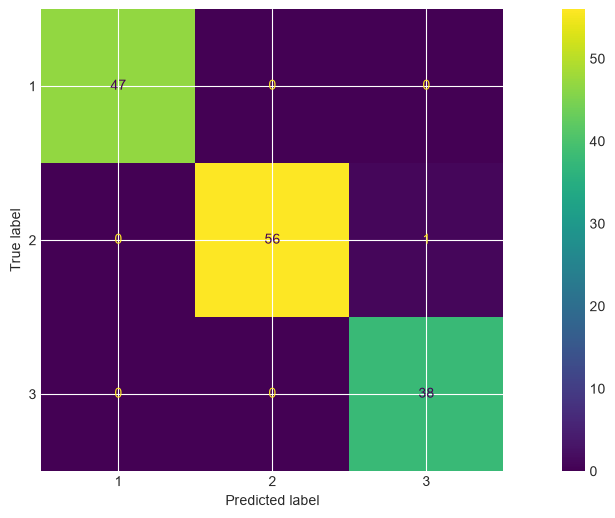

In [31]:
cm=confusion_matrix(y_train,y_pred.argmax(axis=1))
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=[1,2,3])
disp.plot()